**Cuaderno_Proyecto_Definitivo**
_Este es un cuaderno en donde se registra todo lo que se le ha hecho al proyecto en todos los talleres_


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
RUTA_DATASET_PROPIO = 'electric_vehicles_spec_2025.csv.csv'  # <- reemplace por el nombre de su archivo si ya lo tiene

df_propio = pd.read_csv(RUTA_DATASET_PROPIO)
print(df_propio.shape)
df_propio.head()

(478, 22)


,brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,...,towing_capacity_kg,cargo_volume_l,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url
0,Abarth,500e Convertible,155,37.8,Lithium-ion,192.0,235.0,156,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1904/Abarth-500e-C...
1,Abarth,500e Hatchback,155,37.8,Lithium-ion,192.0,235.0,149,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1903/Abarth-500e-H...
2,Abarth,600e Scorpionissima,200,50.8,Lithium-ion,102.0,345.0,158,280,5.9,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3057/Abarth-600e-S...
3,Abarth,600e Turismo,200,50.8,Lithium-ion,102.0,345.0,158,280,6.2,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3056/Abarth-600e-T...
4,Aiways,U5,150,60.0,Lithium-ion,NaN,310.0,156,315,7.5,...,NaN,496,5,FWD,JC - Medium,4680,1865,1700,SUV,https://ev-database.org/car/1678/Aiways-U5


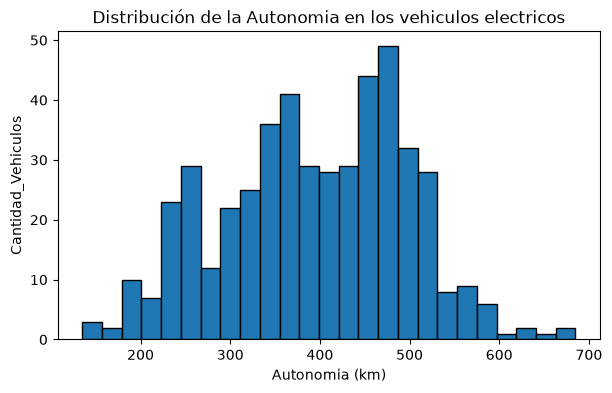

In [3]:
# Grafico 1 de su dataset: reparto de una columna (histograma).
#Graficos para comprender el dataset
fig, ax_uno = plt.subplots(figsize=(7, 4))
ax_uno.hist(df_propio['range_km'], bins=25, edgecolor='black')
ax_uno.set_title('Distribución de la Autonomia en los vehiculos electricos' )
ax_uno.set_xlabel('Autonomia (km)' )
ax_uno.set_ylabel('Cantidad_Vehiculos')
plt.show()


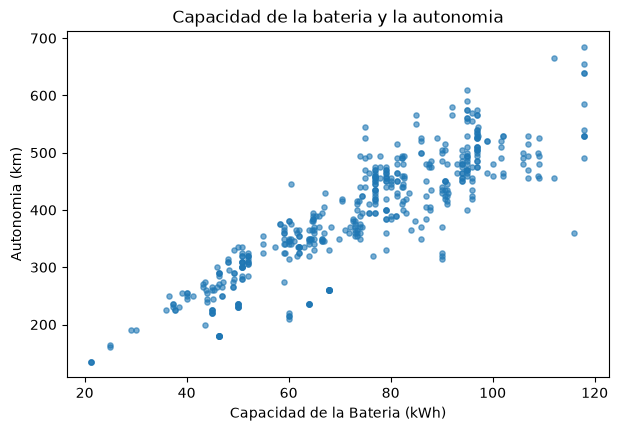

In [4]:
# Grafico 2 de su dataset: relacion entre dos columnas (dispersion).
fig, ax_dos = plt.subplots(figsize=(7, 4.5))
ax_dos.scatter(df_propio['battery_capacity_kWh'], df_propio['range_km'], s=14, alpha=0.6)
ax_dos.set_title('Capacidad de la bateria y la autonomia' )
ax_dos.set_xlabel('Capacidad de la Bateria (kWh)')
ax_dos.set_ylabel('Autonomia (km)')
plt.show()


In [5]:
import numpy as np 
from sklearn.model_selection import train_test_split 


In [6]:
RUTA_DATASET_PROPIO = 'electric_vehicles_spec_2025.csv.csv'  # reemplace por el nombre de su archivo si ya lo tiene
OBJETIVO = 'range_km'  # la columna que quiere predecir, entre comillas
TIPO_TAREA = 'regresion'  # 'regresion' o 'clasificacion'
NUMERICAS_B = [
   'top_speed_kmh',
    'battery_capacity_kWh',
    'number_of_cells',
    'torque_nm',
    'efficiency_wh_per_km',
    'acceleration_0_100_s',
    'fast_charging_power_kw_dc',
    'towing_capacity_kg',
    'seats',
    'length_mm',
    'width_mm',
    'height_mm'
] # lista de columnas numericas de entrada
CATEGORICAS_B = [
    'brand',
    'battery_type',
    'fast_charge_port',
    'drivetrain',
    'segment',
    'car_body_type',
    'model', 
    'source_url',
    'cargo_volume_l'
] # lista de columnas categoricas de entrada (puede ser [])

In [7]:
columnas = [OBJETIVO] + NUMERICAS_B + CATEGORICAS_B  # solo lo que usa el modelo
datos = pd.read_csv(RUTA_DATASET_PROPIO)[columnas]
datos = datos.dropna(subset=[OBJETIVO])  # sin objetivo no hay nada que aprender ni evaluar
print(datos.shape)
datos.head(3)

(478, 22)


,range_km,top_speed_kmh,battery_capacity_kWh,number_of_cells,torque_nm,efficiency_wh_per_km,acceleration_0_100_s,fast_charging_power_kw_dc,towing_capacity_kg,seats,...,height_mm,brand,battery_type,fast_charge_port,drivetrain,segment,car_body_type,model,source_url,cargo_volume_l
0,225,155,37.8,192.0,235.0,156,7.0,67.0,0.0,4,...,1518,Abarth,Lithium-ion,CCS,FWD,B - Compact,Hatchback,500e Convertible,https://ev-database.org/car/1904/Abarth-500e-C...,185
1,225,155,37.8,192.0,235.0,149,7.0,67.0,0.0,4,...,1518,Abarth,Lithium-ion,CCS,FWD,B - Compact,Hatchback,500e Hatchback,https://ev-database.org/car/1903/Abarth-500e-H...,185
2,280,200,50.8,102.0,345.0,158,5.9,79.0,0.0,5,...,1557,Abarth,Lithium-ion,CCS,FWD,JB - Compact,SUV,600e Scorpionissima,https://ev-database.org/car/3057/Abarth-600e-S...,360


In [13]:
from sklearn.pipeline import Pipeline  # cadena de pasos
from sklearn.compose import ColumnTransformer  # un tratamiento por tipo de columna
from sklearn.impute import SimpleImputer  # rellena vacios
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # escala y categorias
from sklearn.linear_model import LinearRegression  # regresion lineal
from sklearn.tree import DecisionTreeRegressor  # arbol de decision
from sklearn.dummy import DummyClassifier  # linea base: siempre la clase mas frecuente
from sklearn.metrics import accuracy_score  # exactitud: proporcion de aciertos
from sklearn.linear_model import LogisticRegression  # regresion logistica: clasifica
import joblib  # guarda y carga modelos entrenados
from sklearn.dummy import DummyRegressor 
from sklearn.metrics import mean_absolute_error 


In [8]:
SEMILLA = 1184


In [9]:
X_b = datos.drop(columns=OBJETIVO)  # entradas
y_b = datos[OBJETIVO]  # objetivo
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_b, y_b, test_size=0.25, random_state=SEMILLA)
print(X_train_b.shape, X_test_b.shape)

(358, 21) (120, 21)


In [15]:
def crear_preproc(numericas, categoricas):
    # Devuelve un preprocesamiento nuevo, igual al de la semana 9.
    tratar_num = Pipeline([('relleno', SimpleImputer(strategy='median')),
                           ('escala', StandardScaler())])
    tratar_cat = Pipeline([('relleno', SimpleImputer(strategy='most_frequent')),
                           ('onehot', OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('num', tratar_num, numericas),
                              ('cat', tratar_cat, categoricas)])

In [16]:
if TIPO_TAREA == 'regresion':
    base_b = DummyRegressor(strategy='mean')  # siempre el promedio de train
    final_b = LinearRegression()
    metrica = 'MAE'
else:
    base_b = DummyClassifier(strategy='most_frequent')  # siempre la clase mas frecuente
    final_b = LogisticRegression(max_iter=1000)
    metrica = 'exactitud'
modelo_b = Pipeline([('preproc', crear_preproc(NUMERICAS_B, CATEGORICAS_B)), ('modelo', final_b)])
print('linea base:', base_b, '| modelo:', final_b, '| metrica:', metrica)

linea base: DummyRegressor() | modelo: LinearRegression() | metrica: MAE


In [17]:
base_b.fit(X_train_b, y_train_b)  # las dos cosas aprenden solo de train
modelo_b.fit(X_train_b, y_train_b)
if metrica == 'MAE':
    valor_base = mean_absolute_error(y_test_b, base_b.predict(X_test_b))  # las dos se miden en test
    valor_modelo = mean_absolute_error(y_test_b, modelo_b.predict(X_test_b))
else:
    valor_base = accuracy_score(y_test_b, base_b.predict(X_test_b))
    valor_modelo = accuracy_score(y_test_b, modelo_b.predict(X_test_b))
print(metrica, '| linea base:', round(valor_base, 3), '| modelo:', round(valor_modelo, 3))

MAE | linea base: 86.114 | modelo: 11.996


In [18]:
datos.to_csv('datos_proyecto.csv', index=False)  # los datos que usa el modelo
joblib.dump(modelo_b, 'modelo_proyecto.joblib')  # el modelo entrenado
resultado_proyecto = pd.DataFrame([{
    'dataset': RUTA_DATASET_PROPIO, 'objetivo': OBJETIVO,
    'tipo_tarea': TIPO_TAREA, 'metrica': metrica,
    'valor_linea_base': round(valor_base, 3), 'valor_modelo': round(valor_modelo, 3),
    'filas_train': len(X_train_b), 'filas_test': len(X_test_b),
}])  # mismas columnas que resultado_carseats.csv
resultado_proyecto.to_csv('resultado_proyecto.csv', index=False)
resultado_proyecto

,dataset,objetivo,tipo_tarea,metrica,valor_linea_base,valor_modelo,filas_train,filas_test
0,electric_vehicles_spec_2025.csv.csv,range_km,regresion,MAE,86.114,11.996,358,120


In [19]:
%%writefile app.py
# app.py - tablero de mi proyecto (se publica el 19 de noviembre)
from pathlib import Path  # rutas de archivos
import pandas as pd  # tablas de datos
import solara  # tablero web
from matplotlib.figure import Figure  # grafico que Solara sabe mostrar

PREGUNTA = '¿Que autonomia puede esperarse de un vehiculo electrico y como influye la capacidad de la bateria de los vehiculos (kWh)?' # la pregunta del proyecto, terminada en signo de interrogacion
COLUMNA_FILTRO = 'battery_capacity_kWh'  # columna numerica de datos_proyecto.csv para el deslizador
ETIQUETA_FILTRO = 'Capacidad de bateria (kWh)'  # nombre de esa columna con su unidad
ETIQUETA_OBJETIVO = 'Autonomia estimada (km)'  # nombre del objetivo con su unidad

Overwriting app.py


In [20]:
%%writefile -a app.py

CARPETA = Path(__file__).parent  # la carpeta donde vive este archivo
datos = pd.read_csv(CARPETA / 'datos_proyecto.csv')  # los datos del martes
resultado = pd.read_csv(CARPETA / 'resultado_proyecto.csv').iloc[0]  # lo que midio el martes
OBJETIVO = resultado['objetivo']  # lo que predice el modelo

def filtrar(tabla, columna, desde, hasta):
    # Devuelve solo las filas con la columna entre desde y hasta (incluidos).
    return tabla[tabla[columna].between(desde, hasta)]

Appending to app.py


In [21]:
%%writefile -a app.py

def texto_resultado(res):
    # Frase honesta: el modelo comparado con la linea base, medido en datos no vistos.
    if res['metrica'] == 'MAE':
        return (f"Adivinar siempre el promedio se equivoca en promedio **{res['valor_linea_base']}**; "
                f"el modelo, **{res['valor_modelo']}**. Medido en {res['filas_test']} filas que el modelo no vio.")
    return (f"Decir siempre la clase mas comun acierta **{res['valor_linea_base']:.0%}**; "
            f"el modelo, **{res['valor_modelo']:.0%}**. Medido en {res['filas_test']} filas que el modelo no vio.")

Appending to app.py


In [22]:
%%writefile -a app.py

def grafico(tabla, columna_x, columna_y, titulo, etiqueta_x, etiqueta_y):
    # Dispersion de dos columnas, con titulo y ejes rotulados.
    fig = Figure(figsize=(6, 4))
    ax = fig.subplots()
    ax.scatter(tabla[columna_x], tabla[columna_y], s=12, alpha=0.6)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel(etiqueta_y)
    return fig


Appending to app.py


In [23]:
%%writefile -a app.py

minimo = float(datos[COLUMNA_FILTRO].min())
maximo = float(datos[COLUMNA_FILTRO].max())
rango = solara.reactive((minimo, maximo))  # estado: empieza con todo el rango

Appending to app.py


In [24]:
%%writefile -a app.py

@solara.component
def Page():
    desde, hasta = rango.value  # el rango que eligio el usuario
    filtradas = filtrar(datos, COLUMNA_FILTRO, desde, hasta)
    solara.Title('Tablero del proyecto')
    solara.Markdown('## ' + PREGUNTA)
    solara.SliderRangeFloat(ETIQUETA_FILTRO, value=rango, min=minimo, max=maximo)
    solara.Markdown(f'Filas en el rango: **{len(filtradas)}** de {len(datos)}')
    if len(filtradas) == 0:
        solara.Markdown('**Ninguna fila cumple el filtro. Amplie el rango.**')
    else:
        solara.FigureMatplotlib(grafico(filtradas, COLUMNA_FILTRO, OBJETIVO, PREGUNTA,
                                        ETIQUETA_FILTRO, ETIQUETA_OBJETIVO))
    with solara.Card('Que tan bueno es el modelo'):
        solara.Markdown(texto_resultado(resultado))

Appending to app.py


In [25]:
from matplotlib.figure import Figure  # grafico que Solara sabe mostrar

def grafico_distribucion(tabla, columna, marca, titulo, etiqueta):
    # Como se reparten los valores de una columna, con el caso del usuario marcado en 
    # rojo.
    fig = Figure(figsize=(6, 3))
    ax = fig.subplots()
    if pd.api.types.is_numeric_dtype(tabla[columna]):
        ax.hist(tabla[columna].dropna(), bins=20, color='lightgray')
        ax.axvline(marca, color='crimson', linewidth=2)
    else:
        conteo = tabla[columna].value_counts()
        ax.bar(conteo.index.astype(str), conteo.values, color=['crimson' if str(v) == str(marca) else 'lightgray' for v in conteo.index])
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel('Numero de filas')
    return fig

In [27]:
import shutil  # copia archivos
from pathlib import Path
from datetime import datetime  # fecha y hora para el nombre de la copia
Path('copias').mkdir(exist_ok=True)
sello = datetime.now().strftime('%Y%m%d-%H%M%S')
for nombre in ['app.py', 'requirements.txt', 'README.md']:
    if Path(nombre).exists():
        shutil.copy(nombre, f'copias/{sello}-{nombre}')  # su version anterior queda guardada
        print('Copia guardada:', f'copias/{sello}-{nombre}')

Copia guardada: copias/20261126-170238-app.py
Copia guardada: copias/20261126-170238-requirements.txt
Copia guardada: copias/20261126-170238-README.md


In [28]:
%%writefile app.py
# app.py - tablero de mi proyecto final (Solara). Se publica el 19 de noviembre.
PREGUNTA = '¿Que autonomia puede esperar un comprador de un vehiculo electrico y como influye la capacidad de la bateria en la autonomia estimada?'  # la pregunta del proyecto, terminada en signo de interrogacion
A_QUIEN = 'Compradores y usuarios interesados en vehiculos electricos que desean comparar opciones segun su autonomia y capacidad de bateria.'  # quien usa el tablero y que decide con el
COLUMNA_FILTRO = 'battery_capacity_kWh' # columna numerica de datos_proyecto.csv para el deslizador
ETIQUETA_FILTRO = 'Capacidad de bateria (kWh)'  # nombre de esa columna con su unidad
ETIQUETA_OBJETIVO = 'Autonomia estimada (km)' # nombre del objetivo con su unidad
FUENTE = 'Electric Car Performance and Battery Dataset'  # enlace si es publico; origen y autorizacion si es privado
ETIQUETAS = {
    'top_speed_kmh': 'Velocidad maxima (km/h)',
    'battery_capacity_kWh': 'Capacidad de bateria (kWh)',
    'number_of_cells': 'Numero de celdas',
    'torque_nm': 'Torque (Nm)',
    'efficiency_wh_per_km': 'Consumo energetico (Wh/km)',
    'acceleration_0_100_s': 'Aceleracion 0-100 km/h (s)',
    'fast_charging_power_kw_dc': 'Potencia de carga rapida (kW)',
    'towing_capacity_kg': 'Capacidad de remolque (kg)',
    'seats': 'Numero de asientos',
    'length_mm': 'Longitud (mm)',
    'width_mm': 'Ancho (mm)',
    'height_mm': 'Altura (mm)',
    'brand': 'Marca',
    'battery_type': 'Tipo de bateria',
    'fast_charge_port': 'Puerto de carga rapida',
    'drivetrain': 'Traccion',
    'segment': 'Segmento',
    'car_body_type': 'Tipo de carroceria',
    'model': 'Modelo',
    'cargo_volume_l': 'Volumen de carga (L)'
}

Overwriting app.py


In [29]:
%%writefile -a app.py

from pathlib import Path  # rutas de archivos
import joblib  # lee el modelo guardado
import pandas as pd  # tablas de datos
import solara  # tablero web
from matplotlib.figure import Figure  # grafico que Solara sabe mostrar

Appending to app.py


In [30]:
%%writefile -a app.py

CARPETA = Path(__file__).parent  # rutas relativas: el servidor no tiene su disco
datos = pd.read_csv(CARPETA / 'datos_proyecto.csv')  # los datos del Taller 14
resultado = pd.read_csv(CARPETA / 'resultado_proyecto.csv').iloc[0]  # la evaluacion en test
modelo = joblib.load(CARPETA / 'modelo_proyecto.joblib')  # el modelo entrenado
OBJETIVO = resultado['objetivo']  # lo que predice el modelo
ENTRADAS = [col for col in datos.columns if col != OBJETIVO]  # todo menos el objetivo

Appending to app.py


In [48]:
%%writefile -a app.py

def filtrar(tabla, columna, desde, hasta):
    # Devuelve solo las filas con la columna entre desde y hasta (incluidos). (Taller 15)
    return tabla[tabla[columna].between(desde, hasta)]

def texto_resultado(res):
    # Frase honesta: el modelo comparado con la linea base, medido en datos no vistos.
    if res['metrica'] == 'MAE':
        return (f"La linea base en el error absoluto medio se equivoco **{round(res['valor_linea_base']),1} km**; "
                f"el modelo se equivoco un:  **{round(res['valor_modelo']),1} km**. Medido en {res['filas_test']} filas que el modelo no vio.")
    return (f"Decir siempre la clase mas comun acierta **{res['valor_linea_base']:.0%}**; "
            f"el modelo, **{res['valor_modelo']:.0%}**. Medido en {res['filas_test']} filas que el modelo no vio.")

Appending to app.py


In [32]:
%%writefile -a app.py

def grafico(tabla, columna_x, columna_y, titulo, etiqueta_x, etiqueta_y):
    # Dispersion de dos columnas, con titulo y ejes rotulados. (Taller 15)
    fig = Figure(figsize=(6, 4))
    ax = fig.subplots()
    ax.scatter(tabla[columna_x], tabla[columna_y], s=12, alpha=0.6)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel(etiqueta_y)
    return fig

Appending to app.py


In [33]:
%%writefile -a app.py

def valor_tipico(serie):
    # Mediana si la columna es numerica; el valor mas comun si no lo es. (Parte 1)
    if pd.api.types.is_integer_dtype(serie):
        return int(round(serie.median()))
    if pd.api.types.is_numeric_dtype(serie):
        return float(serie.median())
    return serie.mode()[0]

def le_gana(res):
    # True si el modelo supera a la linea base en test. (Parte 3)
    if res['metrica'] == 'MAE':
        return res['valor_modelo'] < res['valor_linea_base']
    return res['valor_modelo'] > res['valor_linea_base']

Appending to app.py


In [45]:
%%writefile -a app.py

def texto_prediccion(valor, res):
    # La prediccion de un caso con el error medido en test, en palabras del usuario. (Parte 3)
    if res['metrica'] == 'MAE':
        error = res['valor_modelo']
        return (f"El modelo estima **{valor:.1f} km**. En {res['filas_test']} filas que no vio se equivoco en promedio "
                f"{error} km: espere un valor entre **{valor - error:.1f} km** y **{valor + error:.1f} km**.")
    return (f"El modelo dice **{valor}**. En {res['filas_test']} filas que no vio acerto el {res['valor_modelo']:.0%}; "
            f"decir siempre la clase mas comun acierta el {res['valor_linea_base']:.0%}.")

Appending to app.py


In [35]:
%%writefile -a app.py

def grafico_distribucion(tabla, columna, marca, titulo, etiqueta):
    # Como se reparten los valores de una columna, con el caso del usuario marcado en rojo. (Parte 4)
    fig = Figure(figsize=(6, 3))
    ax = fig.subplots()
    if pd.api.types.is_numeric_dtype(tabla[columna]):
        ax.hist(tabla[columna].dropna(), bins=20, color='lightgray')
        ax.axvline(marca, color='crimson', linewidth=2)
    else:
        conteo = tabla[columna].value_counts()
        ax.bar(conteo.index.astype(str), conteo.values, color=['crimson' if str(v) == str(marca) else 'lightgray' for v in conteo.index])
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel('Numero de filas')
    return fig

Appending to app.py


In [36]:
%%writefile -a app.py

minimo = float(datos[COLUMNA_FILTRO].min())
maximo = float(datos[COLUMNA_FILTRO].max())
rango = solara.reactive((minimo, maximo))  # estado del filtro: empieza con todo el rango
caso = {col: solara.reactive(valor_tipico(datos[col])) for col in ENTRADAS}  # estado del caso: el tipico

Appending to app.py


In [37]:
%%writefile -a app.py

def control(col):
    # Entrada de una columna que solo deja elegir valores que el modelo vio: no se rompe ni extrapola.
    serie, etiqueta = datos[col], ETIQUETAS.get(col, col)
    if pd.api.types.is_integer_dtype(serie):
        solara.SliderInt(etiqueta, value=caso[col], min=int(serie.min()), max=int(serie.max()))
    elif pd.api.types.is_numeric_dtype(serie):
        solara.SliderFloat(etiqueta, value=caso[col], min=float(serie.min()), max=float(serie.max()))
    else:
        solara.Select(etiqueta, value=caso[col], values=sorted(serie.dropna().unique().tolist()))

Appending to app.py


In [38]:
%%writefile -a app.py

@solara.component
def Exploracion():
    desde, hasta = rango.value  # el rango que eligio el usuario
    filtradas = filtrar(datos, COLUMNA_FILTRO, desde, hasta)
    solara.SliderRangeFloat(ETIQUETA_FILTRO, value=rango, min=minimo, max=maximo)
    solara.Markdown(f'Filas en el rango: **{len(filtradas)}** de {len(datos)}')
    if len(filtradas) == 0:
        solara.Markdown('**Ninguna fila cumple el filtro. Amplie el rango.**')
    else:
        solara.FigureMatplotlib(grafico(filtradas, COLUMNA_FILTRO, OBJETIVO, PREGUNTA, ETIQUETA_FILTRO, ETIQUETA_OBJETIVO))
    with solara.Card('Que tan bueno es el modelo'):
        solara.Markdown(texto_resultado(resultado))

Appending to app.py


In [39]:
%%writefile -a app.py

@solara.component
def VistaPrediccion():
    solara.Markdown('## Pruebe un caso')
    for columna in ENTRADAS:
        if columna not in ['source_url', 'model']:
            control(columna)
    tabla_caso = pd.DataFrame([{col: caso[col].value for col in ENTRADAS}])  # el caso, en una fila
    valor = modelo.predict(tabla_caso)[0]
    solara.Markdown(texto_prediccion(valor, resultado))
    if not le_gana(resultado):
        solara.Markdown('**Ojo: este modelo no le gana a la linea base. Tome la estimacion con cautela.**')
    solara.FigureMatplotlib(grafico_distribucion(datos, OBJETIVO, valor, 'Donde cae su caso frente a los datos?', ETIQUETA_OBJETIVO))

Appending to app.py


In [40]:
%%writefile -a app.py

@solara.component
def Page():
    solara.Title('Tablero del proyecto')
    solara.Markdown('## ' + PREGUNTA)
    solara.Markdown('**Para quien:** ' + A_QUIEN)
    Exploracion()
    VistaPrediccion()
    solara.Markdown('**Fuente de los datos:** ' + FUENTE)

Appending to app.py


In [41]:
%%writefile -a app.py
#tercer-grafico

def grafico_carroceria(tabla, columna_cat, columna_y, titulo, etiqueta_x, etiqueta_y):
    # Autonomia promedio por tipo de carroceria, con titulo y ejes con unidad.
    resumen = (
        tabla.groupby(columna_cat, dropna=True)[columna_y]
        .mean()
        .sort_values(ascending=True)
    )
    fig = Figure(figsize=(6, 4))
    ax = fig.subplots()
    ax.barh(resumen.index.astype(str), resumen.values, color='#2b6cb0', alpha=0.85)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel(etiqueta_y)
    fig.tight_layout()
    return fig

Appending to app.py


In [44]:
%%writefile -a app.py

@solara.component
def Exploracion():
    desde, hasta = rango.value  # el rango que eligio el usuario
    filtradas = filtrar(datos, COLUMNA_FILTRO, desde, hasta)
    solara.SliderRangeFloat(ETIQUETA_FILTRO, value=rango, min=minimo, max=maximo)
    solara.Markdown(f'Filas en el rango: **{len(filtradas)}** de {len(datos)}')
    if len(filtradas) == 0:
        solara.Markdown('**Ninguna fila cumple el filtro. Amplie el rango.**')
    else:
        solara.FigureMatplotlib(
            grafico(
                filtradas,
                COLUMNA_FILTRO,
                OBJETIVO,
                '¿Cómo influye la capacidad de batería en la autonomía?',
                ETIQUETA_FILTRO,
                ETIQUETA_OBJETIVO,
            )
        )
        solara.FigureMatplotlib(
            grafico_consumo(
                filtradas,
                'efficiency_wh_per_km',
                OBJETIVO,
                COLUMNA_FILTRO,
                '¿Cómo influye el consumo energético en la autonomía?',
                ETIQUETAS['efficiency_wh_per_km'],
                ETIQUETA_OBJETIVO,
                ETIQUETA_FILTRO,
            )
        )
        solara.FigureMatplotlib(
            grafico_carroceria(
                filtradas,
                'car_body_type',
                OBJETIVO,
                '¿Qué tipo de carrocería ofrece mayor autonomía promedio?',
                ETIQUETA_OBJETIVO,
                ETIQUETAS['car_body_type'],
            )
        )
    with solara.Card('Que tan bueno es el modelo'):
        solara.Markdown(texto_resultado(resultado))

Appending to app.py


In [43]:
%%writefile -a app.py

def grafico_consumo(tabla, columna_x, columna_y, columna_color, titulo, etiqueta_x, etiqueta_y, etiqueta_color):
    # Relacion entre consumo energetico y autonomia, coloreado por capacidad de bateria.
    fig = Figure(figsize=(6, 4))
    ax = fig.subplots()
    dispersion = ax.scatter(
        tabla[columna_x],
        tabla[columna_y],
        c=tabla[columna_color],
        cmap='viridis',
        s=14,
        alpha=0.75,
    )
    barra = fig.colorbar(dispersion, ax=ax)
    barra.set_label(etiqueta_color)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel(etiqueta_y)
    fig.tight_layout()
    return fig

Appending to app.py


In [49]:
%%writefile Dockerfile
FROM python:3.11-slim

WORKDIR /app

# Copiar dependencias e instalarlas
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

# Copiar la app, el cuaderno y los archivos de datos
COPY . .

# Puerto estándar de Solara
EXPOSE 8765

# Arrancar la aplicación Solara
CMD ["solara", "run", "app.py", "--host=0.0.0.0", "--port=8765"]

Writing Dockerfile


In [1]:
import joblib
import pandas as pd

modelo = joblib.load("modelo_proyecto.joblib")
df_prueba = pd.read_csv("datos_proyecto.csv")

# Toma las mismas columnas que espera el pipeline y prueba una predicción
X_prueba = df_prueba[modelo.feature_names_in_].iloc[[0]]
prediccion = modelo.predict(X_prueba)
print("Autonomía estimada (km):", round(float(prediccion[0]), 2))

Autonomía estimada (km): 225.0
